# 03 · Benchmark methods

**Purpose**
- Score four benchmark methods on the **same 2,500 evaluation questions**.
- Methods 1–3 reuse the notebook 02 cache (seconds, no GPU); LXMERT runs its own model.

| # | Method | Source | Why it is here |
|---|---|---|---|
| 1 | Greedy | BLIP-2 (Li et al., 2023) | The standard single-answer baseline: the floor to beat |
| 2 | Majority vote | Self-consistency (Wang et al., 2023) | Same 10 paths, every path counts once → isolates the value of *weighting* |
| 3 | Answer-only weighting | Normalised-probability voting (Wang et al., 2023) | Same paths, weighted by answer confidence only → isolates the value of *grounding* |
| 4 | LXMERT | Tan & Bansal (2019) | Established GQA model, fine-tuned on GQA → external reference |

**Runtime:** T4 GPU is enough (only LXMERT in Step 7 uses it).

## 1 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.utils import load_config, set_seed, gpu_info
from src.errorlog import log_error
from src.gitsync import save_and_push

cfg = load_config()
set_seed(cfg["seed"])
SEED, DATA = cfg["seed"], cfg["paths"]["data"]
print(gpu_info())

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr
Tesla T4 | 15.6 GB | torch 2.11.0+cu130


## 2 · Aggregation and evaluation code
- `src/aggregate.py`: voting over paths, written from scratch (no library voting functions).
- `src/evaluate.py`: accuracy, confidence intervals and paired tests.
- **Confidence intervals resample images, not questions**: ~6 questions share each image, so they are not independent (notebook 01).

In [2]:
%%writefile src/aggregate.py
"""Answer aggregation over cached reasoning paths, implemented from scratch.

Every method reads the same cache (one record per question, k paths each)
and differs only in how much weight each path gets in the vote.
"""

import gzip
import json

import numpy as np
import pandas as pd

from .paths import normalize

SIGNALS = ["lp_mean", "itm", "itc", "ev_lp_mean"]


def load_paths(path: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Read a .jsonl or .jsonl.gz cache into (questions, paths) tables."""
    opener = gzip.open if path.endswith(".gz") else open
    qs, ps = [], []
    with opener(path, "rt") as f:
        for line in f:
            r = json.loads(line)
            qs.append({"id": r["id"], "greedy": normalize(r["greedy"]["answer"]),
                       "greedy_lp": r["greedy"]["lp_mean"]})
            for j, p in enumerate(r["paths"]):
                ps.append({"id": r["id"], "path": j, "template": p["template"],
                           "answer": normalize(p["answer"]), **{s: p[s] for s in SIGNALS}})
    return pd.DataFrame(qs), pd.DataFrame(ps)


def weighted_vote(paths: pd.DataFrame, w) -> pd.DataFrame:
    """Pick, per question, the answer with the largest total path weight.

    Ties are broken by more paths, then by the earliest path (deterministic).
    Returns one row per question: answer, support (winning share of the weight).
    """
    d = paths[["id", "answer", "path"]].assign(w=np.asarray(w, dtype=float), n=1)
    agg = (d.groupby(["id", "answer"], sort=False)
             .agg(w=("w", "sum"), n=("n", "sum"), first=("path", "min")).reset_index())
    agg = agg.sort_values(["id", "w", "n", "first"], ascending=[True, False, False, True])
    total = agg.groupby("id")["w"].sum()
    top = agg.drop_duplicates("id").set_index("id")
    top["support"] = top["w"] / total.loc[top.index]
    return top[["answer", "support"]]


def softmax_weights(paths: pd.DataFrame, score) -> np.ndarray:
    """Turn a per-path score into weights that sum to 1 within each question."""
    s = pd.Series(np.asarray(score, dtype=float), index=paths.index)
    s = s - s.groupby(paths["id"]).transform("max")          # numerical stability
    e = np.exp(s)
    return (e / e.groupby(paths["id"]).transform("sum")).values


# ---- baseline weightings --------------------------------------------------
def majority(paths):
    """Self-consistency (Wang et al., 2023): every path counts once."""
    return weighted_vote(paths, np.ones(len(paths)))


def answer_only(paths):
    """Confidence-weighted voting: weight = exp(mean token log-prob),
    i.e. the 'normalised probability' weighting of Wang et al. (2023)."""
    return weighted_vote(paths, np.exp(paths["lp_mean"].values))

Overwriting src/aggregate.py


In [3]:
%%writefile src/evaluate.py
"""Evaluation: accuracy, image-clustered bootstrap intervals, paired tests."""

import numpy as np
import pandas as pd
from scipy.stats import binomtest


def _cluster_sums(values: np.ndarray, clusters: np.ndarray):
    codes, uniq = pd.factorize(clusters)
    s = np.bincount(codes, weights=values.astype(float))
    n = np.bincount(codes).astype(float)
    return s, n


def cluster_bootstrap(correct, clusters, n_boot: int = 5000, seed: int = 42, alpha: float = 0.05):
    """95% CI for accuracy, resampling whole images (questions on one image are not independent)."""
    s, n = _cluster_sums(np.asarray(correct), np.asarray(clusters))
    rng = np.random.default_rng(seed)
    counts = rng.multinomial(len(s), np.full(len(s), 1 / len(s)), size=n_boot)
    acc = counts @ s / (counts @ n)
    return np.quantile(acc, [alpha / 2, 1 - alpha / 2])


def paired_bootstrap(correct_a, correct_b, clusters, n_boot: int = 5000, seed: int = 42, alpha: float = 0.05):
    """Accuracy difference A - B with an image-clustered bootstrap CI and two-sided p-value."""
    a, b = np.asarray(correct_a, float), np.asarray(correct_b, float)
    sd, n = _cluster_sums(a - b, np.asarray(clusters))
    rng = np.random.default_rng(seed)
    counts = rng.multinomial(len(sd), np.full(len(sd), 1 / len(sd)), size=n_boot)
    diff = counts @ sd / (counts @ n)
    lo, hi = np.quantile(diff, [alpha / 2, 1 - alpha / 2])
    p = min(1.0, 2 * min((diff <= 0).mean(), (diff >= 0).mean()))
    return {"diff": (a - b).mean(), "ci_lo": lo, "ci_hi": hi, "p_boot": p}


def mcnemar(correct_a, correct_b) -> dict:
    """Exact McNemar test on the questions where exactly one method is right."""
    a, b = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    only_a, only_b = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return {"only_A": only_a, "only_B": only_b, "p_mcnemar": p}


def accuracy_table(correct: pd.DataFrame, clusters, seed: int = 42) -> pd.DataFrame:
    """Accuracy (%) with 95% image-clustered bootstrap CI for each column of `correct`."""
    rows = {}
    for m in correct.columns:
        lo, hi = cluster_bootstrap(correct[m].values, clusters, seed=seed)
        rows[m] = {"accuracy": 100 * correct[m].mean(), "ci_low": 100 * lo, "ci_high": 100 * hi}
    return pd.DataFrame(rows).T.round(2)

Overwriting src/evaluate.py


In [4]:
import importlib, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import src.paths, src.aggregate as A, src.evaluate as E
for m in (src.paths, A, E):
    importlib.reload(m)

COLORS = {"Greedy": "#b9b8b2", "Majority vote": "#6250d6", "Answer-only": "#2a78d6", "LXMERT": "#1baf7a"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

## 3 · Load the cached paths
- Read from the compressed copies in `results/` → anyone can rerun this notebook without notebook 02.

In [5]:
read = lambda f: pd.read_csv(f, dtype={"id": str, "imageId": str})
gold = {"eval": read("data/eval_testdev.csv"), "calib": read("data/calib_val.csv")}
for s in gold:
    gold[s]["gold"] = gold[s]["answer"].map(src.paths.normalize)

Q, PTH = {}, {}
for s in ("eval", "calib"):
    Q[s], PTH[s] = A.load_paths(f"results/paths_{s}.jsonl.gz")
    print(f"{s}: {len(Q[s]):,} questions, {len(PTH[s]):,} paths")
PTH["eval"].head()

eval: 2,500 questions, 25,000 paths
calib: 500 questions, 5,000 paths


,id,path,template,answer,lp_mean,itm,itc,ev_lp_mean
0,201153597,0,0,man,-0.401148,0.362320,0.335205,-0.485822
1,201153597,1,0,man,-0.286587,0.926968,0.458252,-1.220290
2,201153597,2,0,man,-0.401148,0.362320,0.335205,-0.485822
3,201153597,3,0,fence,-0.222193,0.336113,0.343750,-2.620853
4,201153597,4,0,man,-0.398561,0.405979,0.340088,-1.657109


## 4 · Run baselines 1–3
- All three see exactly the same paths; only the voting rule changes.
- Ties: more paths wins, then the earliest path (deterministic).

In [6]:
def baseline_preds(s):
    q, p = Q[s].set_index("id"), PTH[s]
    out = pd.DataFrame(index=q.index)
    out["Greedy"] = q["greedy"]
    out["Majority vote"] = A.majority(p)["answer"]
    out["Answer-only"] = A.answer_only(p)["answer"]
    return out

preds = {s: baseline_preds(s) for s in ("eval", "calib")}

def correctness(s, pred):
    g = gold[s].set_index("id")
    pred = pred.reindex(g.index)
    return pred.eq(g["gold"], axis=0), g["imageId"].values

c_eval, img_eval = correctness("eval", preds["eval"])
c_calib, img_calib = correctness("calib", preds["calib"])
pd.concat({"eval (testdev)": E.accuracy_table(c_eval, img_eval, SEED),
           "calib (val)": E.accuracy_table(c_calib, img_calib, SEED)}, axis=1)

eval (testdev)                calib (val)               
                    accuracy ci_low ci_high    accuracy ci_low ci_high
Greedy                 40.20  38.16   42.23        43.4  39.01   47.60
Majority vote          40.68  38.62   42.74        41.6  37.22   45.75
Answer-only            41.12  39.01   43.22        42.4  38.02   46.63

## 5 · Accuracy by question type (eval)
- Overall accuracy hides large differences between types (notebook 01).

In [7]:
def by_type(correct, s, col="structural"):
    g = gold[s].set_index("id").reindex(correct.index)
    t = (correct.groupby(g[col]).mean() * 100).round(1)
    t["n"] = g[col].value_counts()
    return t.sort_values("n", ascending=False)

type_tbl = by_type(c_eval, "eval")
type_tbl

,Greedy,Majority vote,Answer-only,n
structural,,,,
query,27.3,27.9,28.4,1353
verify,58.6,56.8,56.8,447
logical,60.4,61.8,62.7,359
choose,43.8,46.4,47.8,224
compare,50.4,50.4,49.6,117


## 6 · Do the baselines differ significantly? (eval)
- **McNemar**: exact test on questions where only one method is right (classic paired test).
- **Paired bootstrap**: resamples images → accounts for questions sharing an image (stricter).

In [8]:
def compare(c, a, b, imgs):
    return {"A": a, "B": b, "A − B (pts)": 100 * (c[a].mean() - c[b].mean()),
            **E.mcnemar(c[a], c[b]),
            **{k: v for k, v in E.paired_bootstrap(c[a], c[b], imgs, seed=SEED).items() if k != "diff"}}

pairs = [("Majority vote", "Greedy"), ("Answer-only", "Greedy"), ("Answer-only", "Majority vote")]
tests = pd.DataFrame([compare(c_eval, a, b, img_eval) for a, b in pairs])
tests["ci_lo"] *= 100; tests["ci_hi"] *= 100
tests.round(4)

,A,B,A − B (pts),only_A,only_B,p_mcnemar,ci_lo,ci_hi,p_boot
0,Majority vote,Greedy,0.48,94,82,0.4071,-0.6784,1.6387,0.4532
1,Answer-only,Greedy,0.92,97,74,0.0922,-0.2039,2.1036,0.1260
2,Answer-only,Majority vote,0.44,25,14,0.1081,-0.0788,0.9679,0.1028


## 7 · LXMERT
- LXMERT reads **36 object features per image** (from a Faster R-CNN detector) together with the question.
- We use the **original LXMERT features** released by the authors for GQA testdev → faithful to the published setup.
- Model: `unc-nlp/lxmert-gqa-uncased` (fine-tuned on GQA train + val, **never on testdev**).
- Published testdev accuracy: 60.0% (Tan & Bansal, 2019).
- The Hugging Face detector checkpoint used in the official demo has been removed (ERROR_LOG E03), so the released features replace it.

In [9]:
import urllib.request, zipfile, shutil, csv, base64, torch
from transformers import LxmertTokenizer, LxmertForQuestionAnswering

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# 1. original LXMERT object features for GQA testdev (~150 MB, downloaded once to Drive)
TSV = f"{DATA}/raw/gqa_testdev_obj36.tsv"
if not os.path.exists(TSV):
    url = "https://nlp.cs.unc.edu/data/lxmert_data/vg_gqa_imgfeat/gqa_testdev_obj36.zip"
    !wget -q --show-progress -c {url} -O /content/gqa_testdev_obj36.zip
    with zipfile.ZipFile("/content/gqa_testdev_obj36.zip") as z:
        name = [n for n in z.namelist() if n.endswith(".tsv")][0]
        with z.open(name) as fi, open(TSV, "wb") as fo:
            shutil.copyfileobj(fi, fo)

# 2. read features for our images; box coordinates scaled to 0-1 as in the LXMERT code
FIELDS = ["img_id", "img_h", "img_w", "objects_id", "objects_conf",
          "attrs_id", "attrs_conf", "num_boxes", "boxes", "features"]
csv.field_size_limit(2**31 - 1)
need = set(gold["eval"].imageId)
FEATS = {}
with open(TSV) as f:
    for row in csv.DictReader(f, FIELDS, delimiter="\t"):
        if row["img_id"] not in need:
            continue
        n, h, w = int(row["num_boxes"]), float(row["img_h"]), float(row["img_w"])
        boxes = np.frombuffer(base64.b64decode(row["boxes"]), dtype=np.float32).reshape(n, 4).copy()
        boxes[:, (0, 2)] /= w
        boxes[:, (1, 3)] /= h
        feats = np.frombuffer(base64.b64decode(row["features"]), dtype=np.float32).reshape(n, 2048)
        FEATS[row["img_id"]] = {"feats": torch.from_numpy(feats.copy())[None],
                                "boxes": torch.from_numpy(np.clip(boxes, 0, 1))[None]}
print(f"features for {len(FEATS)} / {len(need)} images")

# 3. model (with a mirror as fallback), tokenizer and the 1,842 GQA answer labels
for repo in ["unc-nlp/lxmert-gqa-uncased", "Graphcore/lxmert-gqa-uncased"]:
    try:
        lx = LxmertForQuestionAnswering.from_pretrained(repo).to(DEVICE).eval()
        LX_REPO = repo
        break
    except Exception as e:
        print(f"{repo} unavailable ({type(e).__name__}), trying next")
for tok_repo in [LX_REPO, "unc-nlp/lxmert-base-uncased", "google-bert/bert-base-uncased"]:
    try:
        lx_tok = LxmertTokenizer.from_pretrained(tok_repo)
        break
    except Exception:
        pass
label_url = "https://raw.githubusercontent.com/airsplay/lxmert/master/data/gqa/trainval_label2ans.json"
LABELS = json.load(urllib.request.urlopen(label_url))
print(f"model: {LX_REPO} | tokenizer: {tok_repo} | {len(LABELS)} labels, model expects {lx.config.num_qa_labels}")

/content/gqa_testde 100%[===================>]  80.69M  33.8MB/s    in 2.4s    
features for 392 / 392 images


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/880 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  848MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/455 [00:00<?, ?it/s]

... (2 outputs left out)

tokenizer_config.json:   0%|          | 0.00/153 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model: unc-nlp/lxmert-gqa-uncased | tokenizer: unc-nlp/lxmert-gqa-uncased | 1842 labels, model expects 1842


In [10]:
from tqdm.auto import tqdm

@torch.no_grad()
def lxmert_answer(df_img, f):
    t = lx_tok(list(df_img.question), padding="max_length", max_length=20, truncation=True,
               return_token_type_ids=True, return_attention_mask=True, return_tensors="pt").to(DEVICE)
    n = len(df_img)
    logits = lx(input_ids=t.input_ids, attention_mask=t.attention_mask, token_type_ids=t.token_type_ids,
                visual_feats=f["feats"].to(DEVICE).expand(n, -1, -1),
                visual_pos=f["boxes"].to(DEVICE).expand(n, -1, -1)).question_answering_score
    return [LABELS[i] for i in logits.argmax(-1).tolist()]

ev = gold["eval"]
lx_pred = {}
for k, (img, d) in enumerate(tqdm(ev.groupby("imageId"), desc="LXMERT")):
    if img not in FEATS:
        continue
    for qid, a in zip(d.id, lxmert_answer(d, FEATS[img])):
        lx_pred[qid] = src.paths.normalize(a)
    if k == 0:
        print(pd.DataFrame({"question": d.question.values[:5], "gold": d.answer.values[:5],
                            "LXMERT": [lx_pred[i] for i in d.id[:5]]}))

preds["eval"]["LXMERT"] = pd.Series(lx_pred)
preds["eval"]["LXMERT"].rename("lxmert").to_csv("results/03_lxmert_preds.csv")
print(f"answered {len(lx_pred):,} / {len(ev):,} questions")
print(f"LXMERT accuracy: {100 * (preds['eval']['LXMERT'].reindex(ev.id).values == ev.gold.values).mean():.1f}%")

LXMERT:   0%|          | 0/392 [00:00<?, ?it/s]

                         question  gold LXMERT
0  The fence is in front of what?  bush  plant
1              Which place is it?   zoo    zoo
2      Does this fence look tall?   yes    yes
answered 2,500 / 2,500 questions
LXMERT accuracy: 59.2%


## 8 · All four benchmarks (eval)
- Final benchmark table and figure for the report.
- Note: BLIP-2 methods are **zero-shot** (never trained on GQA); LXMERT is **fine-tuned on GQA** → it is a supervised reference point, not a like-for-like competitor.

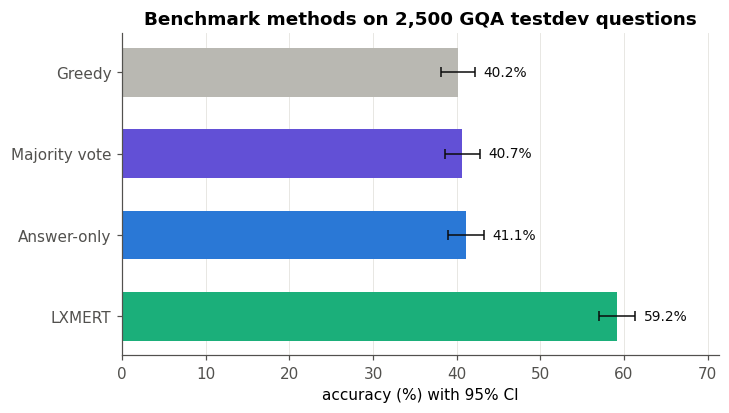

,accuracy,ci_low,ci_high
Greedy,40.20,38.16,42.23
Majority vote,40.68,38.62,42.74
Answer-only,41.12,39.01,43.22
LXMERT,59.20,56.99,61.35


In [11]:
c_eval, img_eval = correctness("eval", preds["eval"])
bench = E.accuracy_table(c_eval, img_eval, SEED)
bench.to_csv("results/03_benchmarks.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(bench))[::-1]
ax.barh(y, bench.accuracy, color=[COLORS[m] for m in bench.index], height=0.6)
ax.errorbar(bench.accuracy, y, xerr=[bench.accuracy - bench.ci_low, bench.ci_high - bench.accuracy],
            fmt="none", ecolor=INK, capsize=3, linewidth=1)
for yi, v, hi in zip(y, bench.accuracy, bench.ci_high):
    ax.text(hi + 1, yi, f"{v:.1f}%", va="center", color=INK, fontsize=9)
ax.set_yticks(y, bench.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("accuracy (%) with 95% CI"); ax.set_xlim(0, bench.ci_high.max() + 10)
ax.set_title("Benchmark methods on 2,500 GQA testdev questions")
plt.savefig("figures/03_benchmarks.png"); plt.show()
bench

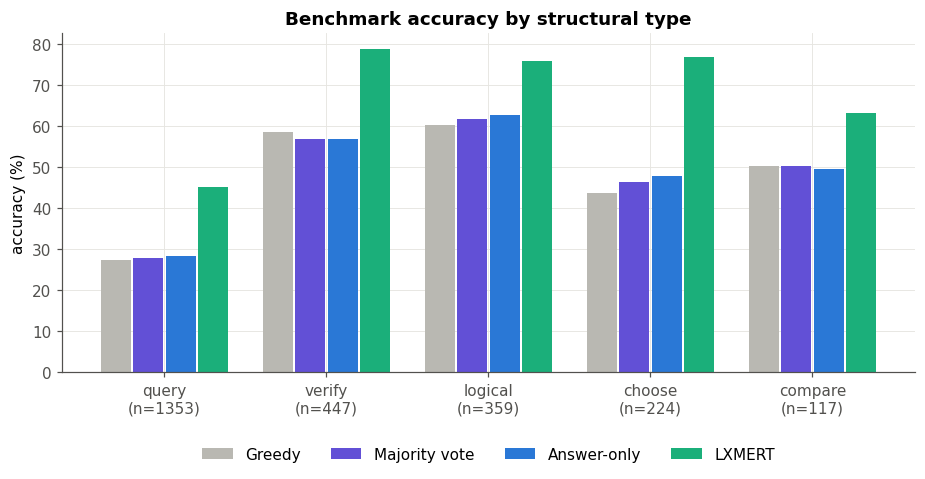

,Greedy,Majority vote,Answer-only,LXMERT,n
structural,,,,,
query,27.3,27.9,28.4,45.1,1353
verify,58.6,56.8,56.8,78.7,447
logical,60.4,61.8,62.7,75.8,359
choose,43.8,46.4,47.8,76.8,224
compare,50.4,50.4,49.6,63.2,117


In [12]:
type_tbl = by_type(c_eval, "eval")
type_tbl.to_csv("results/03_benchmarks_by_type.csv")

methods = [m for m in COLORS if m in type_tbl.columns]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(type_tbl)); w = 0.8 / len(methods)
for i, m in enumerate(methods):
    ax.bar(x + (i - (len(methods) - 1) / 2) * w, type_tbl[m], w * 0.92, color=COLORS[m], label=m)
ax.set_xticks(x, [f"{t}\n(n={n})" for t, n in zip(type_tbl.index, type_tbl.n)])
ax.set_ylabel("accuracy (%)"); ax.set_title("Benchmark accuracy by structural type")
ax.legend(ncol=len(methods), loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.savefig("figures/03_benchmarks_by_type.png"); plt.show()
type_tbl

## 9 · Save predictions for notebook 05
- One row per question, one column per method → notebook 05 adds CW-MPVR and runs all tests from this file.

In [13]:
out = preds["eval"].reindex(gold["eval"].id).copy()
out.index.name = "id"
out.to_csv("results/03_predictions_eval.csv")
out.head()

,Greedy,Majority vote,Answer-only,LXMERT
id,,,,
201153597,man,man,man,trees
201360960,t shirt,hat,hat,shirt
2093863,giraffe,giraffe,giraffe,giraffe
20285195,no,no,no,yes
201175273,cat,cat,cat,curtain


## 10 · Save to GitHub

In [ ]:
save_and_push("notebooks/03_baselines.ipynb", "Add benchmark methods: greedy, majority vote, answer-only weighting, LXMERT")